# How the NoPE anchor adds many numbers in one pass

`runs/anchor_nope_p113_h3_x6` is Nanda's one-layer model with no positional embeddings, trained on chains of 1–3 hops (2–4 operands). It generalizes on every trained hop and extrapolates to 4–6 hops in a single forward pass.

Because it has one layer and no positions, the residual stream at `=` before the MLP is `e(=)` plus attention over the raw embeddings of the prompt. The query at `=` is the same for every prompt, so **each head's attention score to a token depends only on that token's value**. The output therefore depends only on the multiset of operands, never their order. This notebook measures:

1. **Behaviour:** accuracy by hop, including the hop-1 commutativity leak.
2. **Attention scores:** as a function of the operand value, computed from the weights and checked against the forward pass.
3. **Attention vs hop count:** how attention spreads as chains get longer, compared with uniform 1/(h + 2).
4. **What is pooled:** each head's output per token, in the Fourier basis, and how the pooled signal scales with hop count.
5. **The embedding:** which frequencies W_E uses, compared with the hop-1 anchor, and whether the extra ones are harmonics (k·w) of the key frequencies.
6. **The MLP:** how much of each neuron's activity is a function of the total Σx mod p.
7. **The logits:** how well a clock over the total sum, cos(w(Σx − c)), explains them at every hop.

In [1]:
# setup: run from the repo root so paths resolve, and import the code in src/
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import torch as t
import matplotlib.pyplot as plt

import analysis
import mech
import plot_progress as pp
import progress

%matplotlib inline
t.set_grad_enabled(False)
print("torch", t.__version__, "| cuda:", t.cuda.is_available())

/home/saafetensors/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-pwl8uzb6 because there was an issue with the default path (/home/saafetensors/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


torch 2.14.1+cu130 | cuda: False


In [2]:
MUTED = "#c8c7c2"


def panel(ax, title, xlabel, ylabel, log_y=False):
    """style one axis the same way as the run figures.

    args:
        ax: matplotlib axis.
        title: panel title.
        xlabel: x-axis label.
        ylabel: y-axis label.
        log_y: use a log y scale.
    """
    pp.style_axis(ax, title, ylabel, log_y=log_y)
    ax.set_xlabel(xlabel, fontsize=9, color=pp.INK_2)


def freq_bars(ax, norms, highlight, title, ylabel="norm"):
    """bar chart of per-frequency norms, highlighting chosen frequencies and labelling the largest.

    args:
        ax: matplotlib axis.
        norms: tensor of shape (p//2 + 1,) from mech.freq_norms (index 0 is the constant).
        highlight: frequencies drawn in the accent colour.
        title: panel title.
        ylabel: y-axis label.
    """
    f = np.arange(1, len(norms))
    v = norms[1:].cpu().numpy()
    ax.bar(f, v, color=[pp.SERIES[0] if x in highlight else MUTED for x in f], width=0.8)
    for x in np.argsort(-v)[:5]:
        ax.annotate(str(f[x]), (f[x], v[x]), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7, color=pp.INK_2)
    panel(ax, title, "frequency", ylabel)


def new_fig(n_rows, n_cols, width=12.5, height=3.8):
    """make a figure on the shared surface colour.

    args:
        n_rows: rows of panels.
        n_cols: columns of panels.
        width: figure width in inches.
        height: height per row in inches.
    returns:
        (figure, flat list of axes).
    """
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(width, height * n_rows), facecolor=pp.SURFACE, squeeze=False)
    return fig, list(axes.flat)

## Parameters

`CHECKPOINT` can be any file in the run's `checkpoints/`. Extrapolation peaks around step 24k (`step_0024278.pt`) and drifts down slightly by 40k. `REFERENCE_RUN` is the hop-1 anchor, used for comparison.

In [3]:
RUN_DIR = "runs/anchor_nope_p113_h3_x6"
CHECKPOINT = "final.pt"
REFERENCE_RUN = "runs/anchor_p113_h1"
MAX_ROWS_PER_HOP = 2000
DEVICE = "cpu" 

In [4]:
run = analysis.load_run(RUN_DIR, device=DEVICE)
model = analysis.load_model(run, run["run_dir"] / "checkpoints" / CHECKPOINT, DEVICE)
p = run["cfg"].p
basis = progress.fourier_basis(p)
blk = model.core[0][0]
E = model.embed.W_E  # (d_model, p + 1); column p is "="
EQ = p

sets = run["data"]["sets"]
by_hop = {**sets["val"], **sets["extrap_depth"]}
by_hop = {int(h): (x[:MAX_ROWS_PER_HOP], y[:MAX_ROWS_PER_HOP]) for h, (x, y) in by_hop.items()}
measures = progress.progress_measures(model, *run["data"]["grid"], 1)
KEYS = measures["key_freqs"]
print(run["cfg"])
print("key frequencies of the hop-1 logits:", KEYS)
print("logit norm per key frequency:", [round(measures["logit_freq_norms"][f - 1], 1) for f in KEYS])

ModelConfig(p=113, pos='none', n_ctx=0, norm='none', n_prelude=0, k=1, core_shared=True, n_core_copies=1, injection='none', state_init='embed', n_coda=0, state_norm=False, d_model=128, num_heads=4, d_head=32, d_mlp=512)
key frequencies of the hop-1 logits: [32, 50, 10, 16, 49]
logit norm per key frequency: [10567.6, 9703.4, 7154.2, 3139.4, 410.4]


## 1. Behaviour

Accuracy at every hop (1–3 are validation, 4–6 extrapolation). For hop 1, the validation pairs are split by whether their swap `(b, a)` is a training pair. With no positions, the model can't tell `a b =` from `b a =`, so those pairs are effectively seen in training.

In [5]:
hop_cache = {}
for h, (x, y) in by_hop.items():
    logits, cache = mech.run_cache(model, x)
    hop_cache[h] = (x, y, logits, cache)
    loss, acc = mech.loss_and_acc(logits, y)
    print(f"hop {h}: {len(y)} rows, loss {loss:.3f}, acc {acc:.3f}")

x1, y1, logits1, _ = hop_cache[1]
train_pairs = {tuple(r) for r in sets["train"]["1"][0][:, :2].tolist()}
swap_seen = t.tensor([(b, a) in train_pairs for a, b in x1[:, :2].tolist()])
ok = logits1.argmax(-1) == y1
print(f"\nhop-1 val with swap in train:     {ok[swap_seen].float().mean():.3f} ({int(swap_seen.sum())} pairs)")
print(f"hop-1 val with swap not in train: {ok[~swap_seen].float().mean():.3f} ({int((~swap_seen).sum())} pairs)")

hop 1: 1276 rows, loss 0.009, acc 0.998
hop 2: 2000 rows, loss 0.012, acc 0.998
hop 3: 2000 rows, loss 0.100, acc 0.982
hop 4: 2000 rows, loss 0.500, acc 0.940
hop 5: 2000 rows, loss 1.125, acc 0.887
hop 6: 2000 rows, loss 1.715, acc 0.827

hop-1 val with swap in train:     1.000 (378 pairs)
hop-1 val with swap not in train: 0.997 (898 pairs)


## 2. Attention scores depend only on the token

The score of head h from `=` to a token x is s_h(x) = (W_Q e(=)) · (W_K e(x)) / √d_head, the same in every prompt. Below:
- a check that softmax over these scores reproduces the hooked attention on real chains;
- each head's scores over x = 0 … p−1, with the score to `=` itself;
- the frequencies that make up the score function.

largest difference between predicted and hooked attention over all hops: 1.2e-07
head 0: s(=) = +0.20; s(x) mean -0.10, sd 0.13, range -0.41..+0.18; exp(s) varies 1.81x; top freqs [10, 32, 50, 20, 6]; key-frequency share 0.65
head 1: s(=) = +0.25; s(x) mean -0.07, sd 0.11, range -0.44..+0.21; exp(s) varies 1.91x; top freqs [10, 32, 50, 16, 31]; key-frequency share 0.62
head 2: s(=) = -1.56; s(x) mean +0.07, sd 0.14, range -0.37..+0.50; exp(s) varies 2.38x; top freqs [10, 32, 16, 50, 26]; key-frequency share 0.62
head 3: s(=) = +0.21; s(x) mean -0.13, sd 0.15, range -0.54..+0.17; exp(s) varies 2.05x; top freqs [10, 32, 50, 16, 40]; key-frequency share 0.72


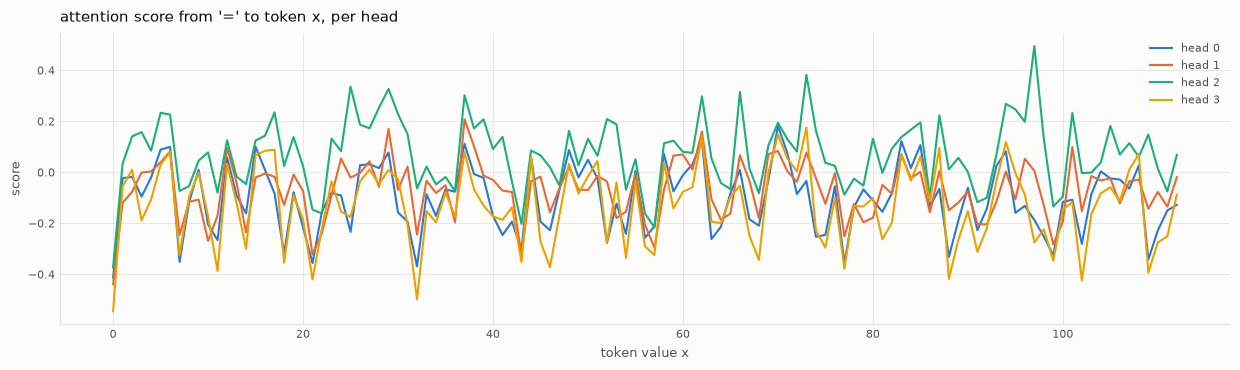

In [6]:
scores = mech.head_scores(blk.attn, E[:, EQ], E.T)  # (heads, p + 1)
worst = 0.0
for h, (x, y, logits, cache) in hop_cache.items():
    hooked = cache[("core.0.0.attn.hook_attn", 0)][:, :, -1]  # (rows, heads, positions)
    predicted = scores[:, x].permute(1, 0, 2).softmax(-1)
    worst = max(worst, (predicted - hooked).abs().max().item())
print(f"largest difference between predicted and hooked attention over all hops: {worst:.1e}")

n_heads = scores.shape[0]
for h in range(n_heads):
    s = scores[h, :p]
    norms = mech.freq_norms(s[None] - s.mean(), basis)[1:]
    top = (norms.argsort(descending=True)[:5] + 1).tolist()
    key_share = (norms[[f - 1 for f in KEYS]].pow(2).sum() / norms.pow(2).sum()).item()
    print(f"head {h}: s(=) = {scores[h, EQ]:+.2f}; s(x) mean {s.mean():+.2f}, sd {s.std():.2f}, "
          f"range {s.min():+.2f}..{s.max():+.2f}; exp(s) varies {float(s.exp().max() / s.exp().min()):.2f}x; "
          f"top freqs {top}; key-frequency share {key_share:.2f}")

fig, axes = new_fig(1, 1, width=12.5)
xs = list(range(p))
pp.draw_lines(axes[0], xs, [(f"head {h}", scores[h, :p].tolist()) for h in range(n_heads)], end_labels=False)
panel(axes[0], "attention score from '=' to token x, per head", "token value x", "score")
plt.tight_layout(); plt.show()

## 3. Attention vs hop count

For each hop count: the weight each head puts on `=` itself, and the mean weight per operand, compared with uniform attention 1/(h + 2). If attention stays close to uniform, each operand's share of the pooled signal shrinks as chains get longer: attention dilution.

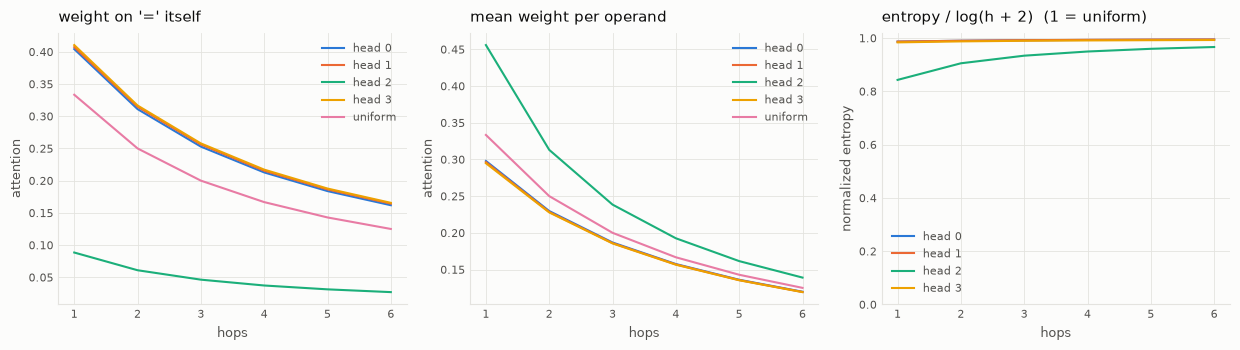

head 0: weight on '=' by hop [0.404, 0.311, 0.253, 0.213, 0.184, 0.162]; per operand [0.298, 0.23, 0.187, 0.157, 0.136, 0.12]
head 1: weight on '=' by hop [0.407, 0.315, 0.256, 0.215, 0.186, 0.164]; per operand [0.296, 0.228, 0.186, 0.157, 0.136, 0.119]
head 2: weight on '=' by hop [0.088, 0.061, 0.046, 0.037, 0.031, 0.027]; per operand [0.456, 0.313, 0.238, 0.193, 0.161, 0.139]
head 3: weight on '=' by hop [0.41, 0.317, 0.258, 0.217, 0.188, 0.166]; per operand [0.295, 0.228, 0.186, 0.157, 0.135, 0.119]


In [7]:
hops = sorted(hop_cache)
on_eq = {h: [] for h in range(n_heads)}
per_op = {h: [] for h in range(n_heads)}
ent = {h: [] for h in range(n_heads)}
for hop in hops:
    a = hop_cache[hop][3][("core.0.0.attn.hook_attn", 0)][:, :, -1]
    for h in range(n_heads):
        on_eq[h].append(a[:, h, -1].mean().item())
        per_op[h].append(a[:, h, :-1].mean().item())
        ent[h].append((mech.entropy(a[:, h]).mean() / np.log(hop + 2)).item())
uniform = [1 / (hop + 2) for hop in hops]

fig, axes = new_fig(1, 3, height=3.6)
pp.draw_lines(axes[0], hops, [(f"head {h}", on_eq[h]) for h in range(n_heads)] + [("uniform", uniform)], end_labels=False)
panel(axes[0], "weight on '=' itself", "hops", "attention")
pp.draw_lines(axes[1], hops, [(f"head {h}", per_op[h]) for h in range(n_heads)] + [("uniform", uniform)], end_labels=False)
panel(axes[1], "mean weight per operand", "hops", "attention")
pp.draw_lines(axes[2], hops, [(f"head {h}", ent[h]) for h in range(n_heads)], ylim=(0, 1.02), end_labels=False)
panel(axes[2], "entropy / log(h + 2)  (1 = uniform)", "hops", "normalized entropy")
plt.tight_layout(); plt.show()
for h in range(n_heads):
    print(f"head {h}: weight on '=' by hop {[round(v, 3) for v in on_eq[h]]}; per operand {[round(v, 3) for v in per_op[h]]}")

### Attention vs operand values

On the hop-1 table, the weight a head puts on `a` depends on both `a` and `b`, through the shared softmax denominator. Shown for every head, with how much of the variation the key-frequency terms explain.

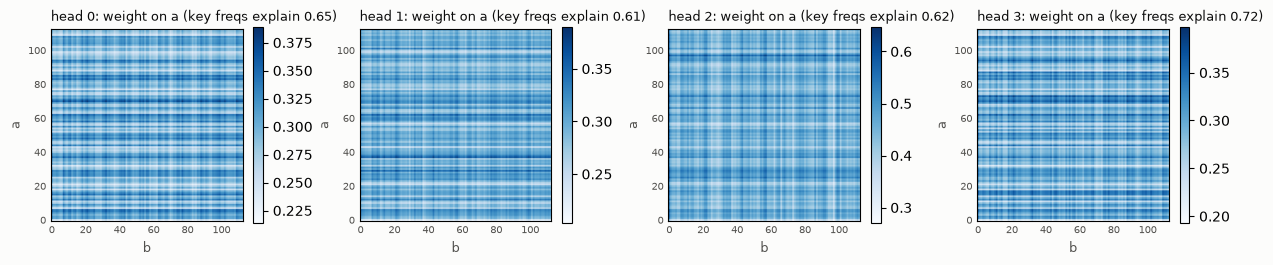

In [8]:
a_idx, b_idx = t.meshgrid(t.arange(p), t.arange(p), indexing="ij")
grid_x = t.stack([a_idx.flatten(), b_idx.flatten(), t.full((p * p,), EQ)], 1)
grid_attn = scores[:, grid_x].permute(1, 0, 2).softmax(-1)[:, :, 0].reshape(p, p, n_heads)
kept = mech.keep_frequencies_2d(grid_attn, basis, KEYS)
r2 = 1 - (grid_attn - kept).pow(2).sum((0, 1)) / (grid_attn - grid_attn.mean((0, 1))).pow(2).sum((0, 1))
fig, axes = new_fig(1, n_heads, height=3.2)
for h, ax in enumerate(axes):
    im = ax.imshow(grid_attn[:, :, h].cpu(), cmap="Blues", origin="lower")
    ax.set_title(f"head {h}: weight on a (key freqs explain {r2[h]:.2f})", loc="left", fontsize=9, color=pp.INK)
    ax.set_xlabel("b", fontsize=9, color=pp.INK_2); ax.set_ylabel("a", fontsize=9, color=pp.INK_2)
    ax.tick_params(labelsize=7, colors=pp.INK_2, length=0)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

## 4. What gets pooled

Each head writes W_O W_V e(x) for every token it attends to, scaled by the attention weight. Below:
- the Fourier content of what each head writes as a function of x;
- how large the pooled operand signal at `=` is as chains get longer. With uniform attention it would shrink like (h + 1)/(h + 2) times an average of per-token vectors: the average of more vectors at random phases is smaller.

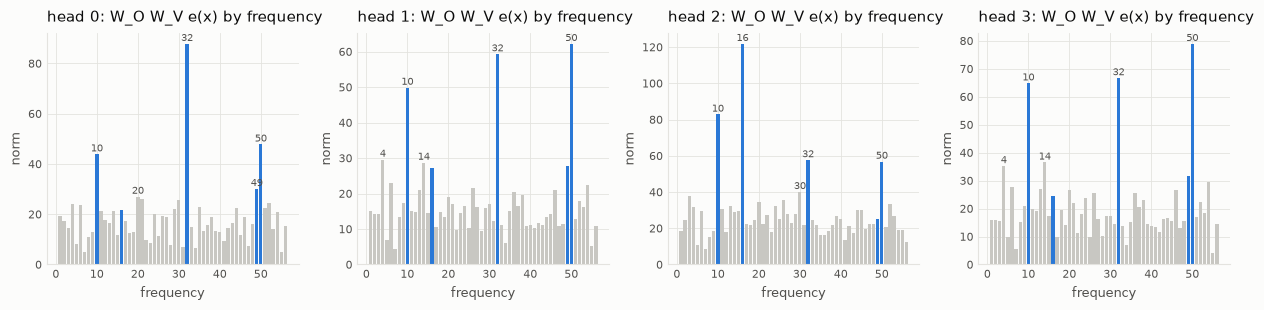

norm of the attention output at '=' that comes from operands (mean over rows):
  hop 1: operand part 30.98, whole attention output 41.67
  hop 2: operand part 28.04, whole attention output 34.83
  hop 3: operand part 26.59, whole attention output 31.10
  hop 4: operand part 25.50, whole attention output 28.56
  hop 5: operand part 24.29, whole attention output 26.41
  hop 6: operand part 23.17, whole attention output 24.71


In [9]:
vals = mech.head_values(blk.attn, E.T)  # (heads, p + 1, d_model)
fig, axes = new_fig(1, n_heads, height=3.2)
for h, ax in enumerate(axes):
    norms = mech.freq_norms(vals[h, :p].T, basis)
    freq_bars(ax, norms, KEYS, f"head {h}: W_O W_V e(x) by frequency")
plt.tight_layout(); plt.show()

print("norm of the attention output at '=' that comes from operands (mean over rows):")
for hop in hops:
    x, y, logits, cache = hop_cache[hop]
    a = cache[("core.0.0.attn.hook_attn", 0)][:, :, -1, :-1]  # (rows, heads, operands)
    from_ops = sum(t.einsum('ro,rod->rd', a[:, h], vals[h][x[:, :-1]]) for h in range(n_heads))
    total = cache[("core.0.0.hook_attn_out", 0)][:, -1]
    print(f"  hop {hop}: operand part {from_ops.norm(dim=-1).mean():.2f}, whole attention output {total.norm(dim=-1).mean():.2f}")

## 5. The embedding

W_E's norm at each frequency, for this model and the hop-1 anchor. The hop-1 anchor's embedding is close to pure key frequencies. To add n numbers by pooling, a model could use harmonics: the product of the clock phases e^{iw x_j} over the operands is a polynomial in the power sums Σ_j e^{ikw x_j} for k = 1 … n (Newton's identities). That would need frequencies k·w. The table checks how much of W_E's norm sits on harmonics of the key frequencies, against what a random set of the same size would hold.

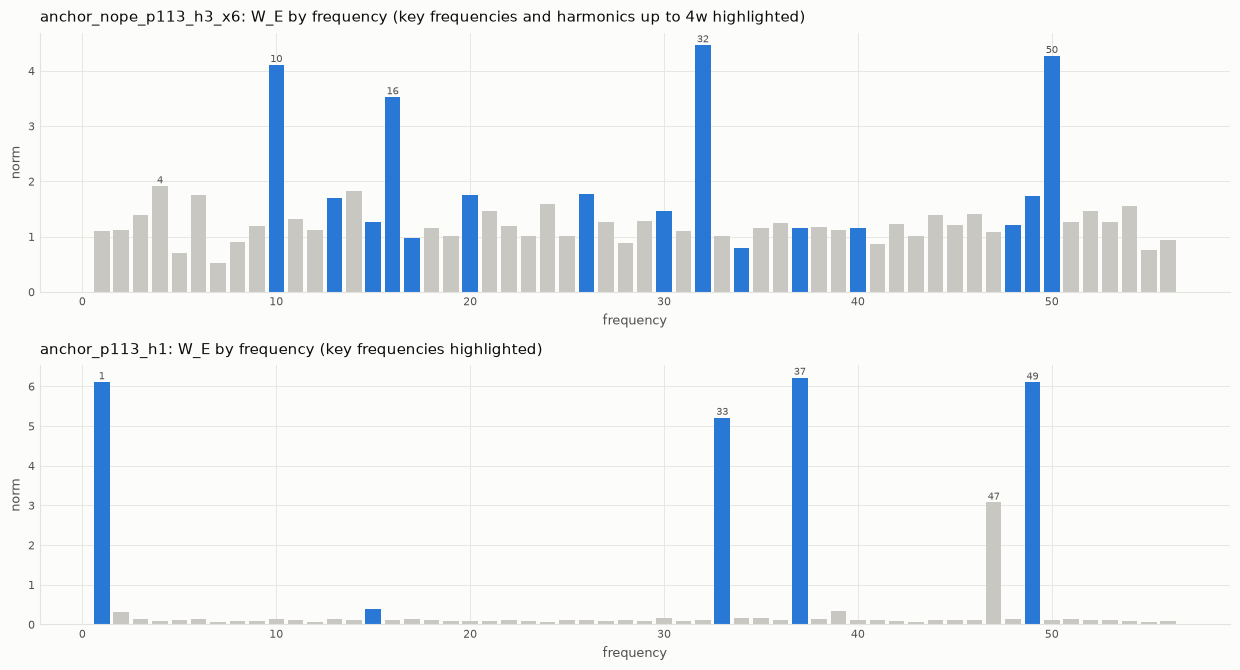

gini: this model 0.234, hop-1 anchor 0.769
set                          size  share of W_E norm^2  random set of that size
harmonics k <= 1                5                0.467                    0.089
harmonics k <= 2                8                0.517                    0.143
harmonics k <= 3               13                0.560                    0.232
harmonics k <= 4               15                0.590                    0.268

15 largest W_E frequencies: [32, 50, 10, 16, 4, 14, 26, 20, 6, 49, 13, 24, 54, 30, 52]
of these, harmonics (k <= 4) of the key frequencies: [32, 50, 10, 16, 26, 20, 49, 13, 30]
of these, sums or differences of two key frequencies: [32, 16, 14, 26, 20, 6, 49, 13, 54]
keys W_K e(x): top frequencies [10, 32, 50, 16, 20, 6, 31, 14], gini 0.341
values W_V e(x): top frequencies [32, 50, 10, 16, 4, 14, 49, 6], gini 0.256


In [10]:
ref = analysis.load_run(REFERENCE_RUN, device=DEVICE)
ref_model = analysis.load_model(ref, ref["run_dir"] / "checkpoints" / "final.pt", DEVICE)
ref_keys = progress.progress_measures(ref_model, *ref["data"]["grid"], 1)["key_freqs"]
norms = mech.freq_norms(E[:, :p], basis)
ref_norms = mech.freq_norms(ref_model.embed.W_E[:, :p], basis)
fig, axes = new_fig(2, 1, height=3.4)
freq_bars(axes[0], norms, mech.harmonics(KEYS, 4, p), f"{run['name']}: W_E by frequency (key frequencies and harmonics up to 4w highlighted)")
freq_bars(axes[1], ref_norms, ref_keys, f"{ref['name']}: W_E by frequency (key frequencies highlighted)")
plt.tight_layout(); plt.show()

sq = norms[1:].pow(2)
total = sq.sum().item()
print(f"gini: this model {progress.gini(norms[1:]):.3f}, hop-1 anchor {progress.gini(ref_norms[1:]):.3f}")
print(f"{'set':<28} {'size':>4} {'share of W_E norm^2':>20} {'random set of that size':>24}")
for k in (1, 2, 3, 4):
    H = mech.harmonics(KEYS, k, p)
    share = sq[[f - 1 for f in H]].sum().item() / total
    print(f"{'harmonics k <= ' + str(k):<28} {len(H):>4} {share:>20.3f} {len(H) / (p // 2):>24.3f}")
top = (sq.argsort(descending=True)[:15] + 1).tolist()
print("\n15 largest W_E frequencies:", top)
print("of these, harmonics (k <= 4) of the key frequencies:", [f for f in top if f in mech.harmonics(KEYS, 4, p)])
pairs = sorted({mech.fold(f + g, p) for f in KEYS for g in KEYS} | {mech.fold(f - g, p) for f in KEYS for g in KEYS} - {0})
print("of these, sums or differences of two key frequencies:", [f for f in top if f in pairs])

kq = t.einsum('ihd,dx->ihx', blk.attn.W_K, E[:, :p]).reshape(-1, p)
vq = t.einsum('ihd,dx->ihx', blk.attn.W_V, E[:, :p]).reshape(-1, p)
for name, M in [("keys W_K e(x)", kq), ("values W_V e(x)", vq)]:
    n = mech.freq_norms(M, basis)[1:]
    print(f"{name}: top frequencies {(n.argsort(descending=True)[:8] + 1).tolist()}, gini {progress.gini(n):.3f}")

## 6. The MLP: where does the total appear?

For each hop count, the share of variance explained by grouping prompts by **Σx mod p** (the answer), with the first and last operand alone as controls. It is measured at two places:
- **Neurons:** the MLP activations at `=`, weighting each neuron by its variance.
- **MLP → logits:** what the MLP writes to the logits, `acts @ W_L`.

In Nanda's model each neuron mixes single-operand terms (cos wa, cos wb) with product terms, so a neuron need not be a function of the sum even when the output is. On the hop-1 table, the Nanda-style single-frequency analysis is repeated for comparison with the hop-1 anchor.

In [11]:
W_L = blk.mlp.W_out.T @ model.unembed.W_U  # (d_mlp, p)


def explained(acts, labels):
    """variance-weighted share of all columns' variance explained by the labels.

    args:
        acts: tensor of shape (n, k).
        labels: int tensor of shape (n,).
    returns:
        float.
    """
    var = acts.var(0)
    return (mech.variance_explained_by(acts, labels) * var / var.sum()).sum().item()


print("chance: grouping n rows into k groups explains about (k - 1) / (n - 1) of any variance\n")
print(f"{'':>3} {'':>7} {'neurons':^30} {'mlp -> logits':^30}")
print(f"{'hop':>3} {'chance':>7} {'by sum':>9} {'by first':>9} {'by last':>9}   {'by sum':>9} {'by first':>9} {'by last':>9}")
for hop in hops:
    x, y, logits, cache = hop_cache[hop]
    acts = cache[("core.0.0.mlp.hook_post", 0)][:, -1]
    chance = (p - 1) / (len(y) - 1)
    cols = [explained(m, lab) for m in (acts, acts @ W_L) for lab in (y, x[:, 0], x[:, -2])]
    print(f"{hop:>3} {chance:>7.3f} " + " ".join(f"{v:>9.3f}" for v in cols[:3]) + "   " + " ".join(f"{v:>9.3f}" for v in cols[3:]))

grid_tokens = run["data"]["grid"][0]
_, gcache = mech.run_cache(model, grid_tokens)
grid = gcache[("core.0.0.mlp.hook_post", 0)][:, -1].reshape(p, p, -1)
live = grid.pow(2).sum((0, 1)) > 1e-8
best, frac = mech.neuron_frequencies(mech.fourier_2d(grid, basis))
best, frac = best[live], frac[live]
print(f"\nhop-1 table: {int(live.sum())} live neurons; one frequency explains > 0.85 for {(frac > 0.85).float().mean():.3f} "
      f"(> 0.5 for {(frac > 0.5).float().mean():.3f})")
counts = {f: int(((best == f) & (frac > 0.5)).sum()) for f in sorted(set(best.tolist()))}
print("neurons per best frequency (explained > 0.5):", {f: c for f, c in sorted(counts.items(), key=lambda kv: -kv[1]) if c})

chance: grouping n rows into k groups explains about (k - 1) / (n - 1) of any variance

                       neurons                     mlp -> logits         
hop  chance    by sum  by first   by last      by sum  by first   by last
  1   0.088     0.139     0.442     0.432       0.780     0.180     0.173
  2   0.056     0.079     0.275     0.288       0.728     0.146     0.150
  3   0.056     0.063     0.223     0.225       0.645     0.143     0.155
  4   0.056     0.061     0.195     0.181       0.558     0.137     0.142
  5   0.056     0.066     0.166     0.167       0.467     0.124     0.141
  6   0.056     0.063     0.147     0.151       0.380     0.123     0.131



hop-1 table: 443 live neurons; one frequency explains > 0.85 for 0.000 (> 0.5 for 0.000)
neurons per best frequency (explained > 0.5): {}


## 7. The logits: a clock over the total sum

At every hop, fit logit(c) by cos/sin(w(Σx − c)) at the key frequencies, with one amplitude and phase per frequency shared by all prompts. The table reports:
- **clock R²:** the share of the row-centred logit variance the fit explains;
- **clock amplitude:** the standard deviation over c of the fitted clock, and that amplitude times (h + 2), which is constant if the clock is diluted exactly like uniform attention;
- **other:** the standard deviation of everything else;
- **restricted loss:** cross-entropy using only the fitted clock;
- **excluded loss:** cross-entropy after subtracting it.

The fitted clock always peaks at the true sum, so its accuracy is 1 by construction and isn't shown. What matters is how its amplitude compares with the rest of the logits.

In [12]:
print(f"{'hop':>3} {'acc':>6} {'loss':>7} {'clock R^2':>10} {'clock amplitude':>16} {'x (h + 2)':>10} {'other':>7} {'restricted loss':>16} {'excluded loss':>14}")
for hop in hops:
    x, y, logits, cache = hop_cache[hop]
    fitted, r2 = mech.clock_fit(logits, y, KEYS, p)
    loss, acc = mech.loss_and_acc(logits, y)
    rest = logits - logits.mean(-1, keepdim=True) - fitted
    rl, _ = mech.loss_and_acc(fitted, y)
    el, _ = mech.loss_and_acc(logits - fitted, y)
    amp = fitted.std(-1).mean().item()
    print(f"{hop:>3} {acc:>6.3f} {loss:>7.3f} {r2:>10.3f} {amp:>16.2f} {amp * (hop + 2):>10.1f} {rest.std(-1).mean():>7.2f} {rl:>16.3f} {el:>14.3f}")

hop    acc    loss  clock R^2  clock amplitude  x (h + 2)   other  restricted loss  excluded loss
  1  0.998   0.009      0.880            13.30       39.9    4.82            0.000         12.149
  2  0.998   0.012      0.884            10.18       40.7    3.62            0.000          9.392
  3  0.982   0.100      0.862             8.05       40.2    3.09            0.002          8.294
  4  0.940   0.500      0.787             6.51       39.0    2.95            0.013          7.975
  5  0.887   1.125      0.678             5.40       37.8    2.96            0.046          7.884
  6  0.827   1.715      0.561             4.55       36.4    3.04            0.122          7.903


## Reading

Numbers are for `final.pt`.

**What it computes.** At every hop the logits are a clock over the total sum.
- A fit of cos/sin(w(Σx − c)) with 4 key frequencies (32, 50, 10, 16) explains 0.88 of the logit variance at hops 1–2, falling to 0.56 at hop 6.
- Removing the fitted clock raises the loss to 8–12 at every hop.
- The hop-1 result is real, not leakage: accuracy is 0.997 on val pairs whose swap was never trained.

**Why longer chains fail: attention dilution, quantitatively.**
- Attention from `=` is close to mean pooling. Each head's score varies only by a factor of 1.8–2.4 in exp(s) across token values, and that modulation sits at the key frequencies.
- Normalized entropy is ≥ 0.98 for heads 0, 1 and 3. Head 2 gives `=` almost no weight (0.09 → 0.03 over hops 1–6) and is slightly more selective (0.84 → 0.97).
- **Clock amplitude × (h + 2) is nearly constant:** 39.9, 40.7, 40.2, 39.0 for hops 1–4, then 37.8 and 36.4 at hops 5 and 6. So the clock shrinks exactly like a uniform average over the h + 2 tokens.
- Meanwhile the non-clock part of the logits falls from 4.8 at hop 1 to about 3 by hop 3, then stays flat. Accuracy falls (0.94 / 0.89 / 0.83 at hops 4–6) as the clock shrinks toward that floor.
- Prediction, untested: the clock (about 40/(h + 2)) would sink to the size of the floor around h ≈ 11, so accuracy should keep falling steadily past 6 hops. Testing it needs longer extrapolation sets.

**The embedding is dense, not a few clean frequencies.**
- W_E's gini is 0.23, versus 0.77 for the hop-1 anchor. The 4 key frequencies hold 47% of its norm², and the rest is spread out.
- Several of the larger extra frequencies are sums or differences of two key frequencies, e.g. 26 = 10+16, 6 = 16−10, 20 = 2·10, 13 = 2·50 mod 113.
- Pure harmonics (k·w) are only modestly over-represented: 59% of the norm² sits on harmonics up to 4w, against 27% for a random set of the same size.
- The Newton's-identities idea (power sums at k·w) is therefore weakly supported at best. Second-order combinations of key frequencies fit better.

**The MLP assembles the sum across neurons, not within them.**
- No hop-1 neuron is explained > 0.5 by a single frequency, versus 75% > 0.85 in the hop-1 anchor.
- Neuron activations depend on individual operands (first operand: 0.44 at hop 1, chance 0.09) and barely on the sum. From hop 2 on, the sum explains about as much as chance (~0.06).
- What the MLP writes to the logits *is* a function of the sum: 0.78 of its variance at hop 1, falling to 0.38 at hop 6.
- So the representation is distributed. The total only appears once the neurons are combined through W_out and W_U.

**Open:** how the MLP turns a near-uniform average of per-token features into cos(w·Σx) for up to 7 operands. Next steps:
- ablate frequency groups of W_E (keys only; keys plus pairwise sums and differences) and see which hop counts break;
- fit neuron pre-activations as functions of the pooled cos/sin(k·w·x) averages.